# PCA: historia del último intervalo y renovación de candidatos

Se conserva PCA centrada + media al 95%, k puntos por QR directo y 128−k Sobol; reconstrucción cada 100 pasos, pérdida histórica, red y Adam, diez semillas y 10000 pasos de continuación.

**Referencia previa:** ventana de 20 snapshots, uno nuevo cada 100 pasos después del warmup, candidatos fijos. **Intervalo fijo:** 20 snapshots posteriores a cada quinto paso del último intervalo de 100, candidatos fijos. **Intervalo renovado:** la misma cadencia e historia, con 4096 candidatos Sobol nuevos por intervalo.

La primera selección es idéntica y usa la historia del warmup común. Después se recolecta la siguiente historia mientras se entrena sobre el lote ya elegido. En la variante renovada se genera un nuevo conjunto al comenzar la recolección y se mantiene fijo durante los 20 snapshots: cada fila siempre corresponde a una coordenada. No se concatenan residuos de coordenadas distintas. Los snapshots se toman después de actualizar Adam. Los últimos candidatos observados al terminar no se utilizan para otra selección.

**Alcance causal:** referencia frente a intervalo fijo cambia conjuntamente cadencia y memoria temporal; no atribuye efectos únicamente a borrar la historia. Intervalo fijo frente a renovado sí aísla el cambio de candidatos. Los dos brazos nuevos comparten frecuencia, duración y presupuesto de observación. El costo de observar es mayor que en la referencia; no se afirma aceleración. El número k puede cambiar por el nuevo espectro. Sobol es el control general reutilizado.

| Método | RMSE prueba ± DE | Residuo RMS |
|---|---:|---:|
| Ventana previa, candidatos fijos | 0.07715 ± 0.02436 | 0.10882 |
| Último intervalo, candidatos fijos | 0.07144 ± 0.00977 | 0.16801 |
| Último intervalo, candidatos renovados | 0.07096 ± 0.01749 | 0.16187 |
| Sobol completo | 0.05722 ± 0.01961 | 0.31074 |


Último intervalo, candidatos fijos frente a Ventana previa, candidatos fijos: diferencia RMSE -0.00571, mejora en 6/10 semillas.

Último intervalo, candidatos renovados frente a Último intervalo, candidatos fijos: diferencia RMSE -0.00047, mejora en 5/10 semillas.

**Comparación**

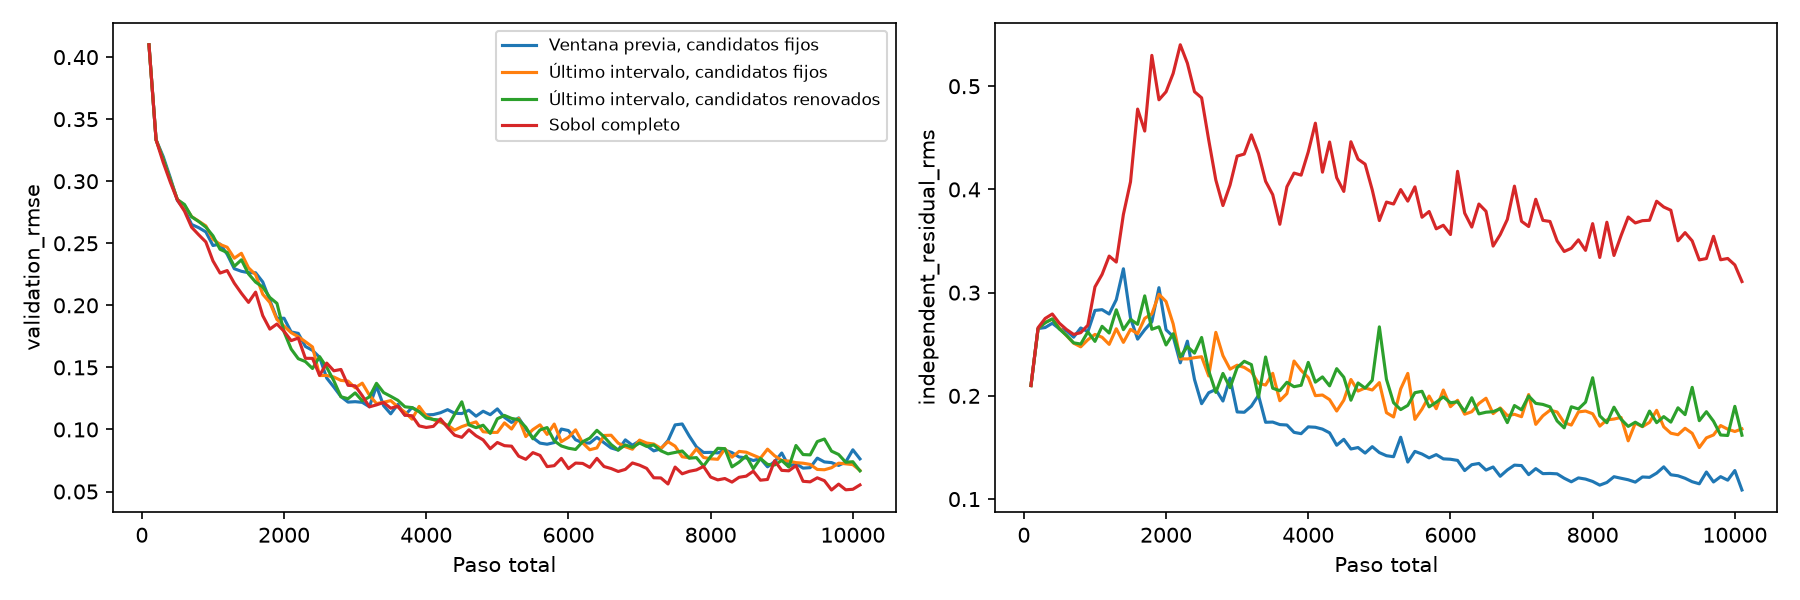

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/interval_history/interval20_every5_10_seeds_10k_v1/comparison.png'), format='png', embed=True))


Se evalúa el modelo terminal en tiempos de prueba reservados, sin elegir por prueba. Las referencias anteriores se reutilizan; métricas y trazas identifican su método. history_intervals.csv guarda los pasos de cada intervalo y history_audit.npz guarda coordenadas y matrices con signo. Se verifica historia inicial común, candidatos fijos frente a renovados y forma/cadencia de las historias. Las figuras están incrustadas como PNG.

Ejecutar `python scripts/run_collocation_intervals.py`; las corridas completas se reutilizan. El control posterior podrá separar frecuencia de observación y duración de la memoria.